# От чего зависит цена автомобиля в объявлениях Drom

## Описание данных

В работе я использую датасет [Car Sales Information](https://www.kaggle.com/datasets/ekibee/car-sales-information) с Kaggle. В нём собраны объявления о продаже автомобилей с сайта Drom.ru за 2023 год. Наблюдением является одно объявление: в нём указаны характеристики автомобиля (марка, модель, год выпуска, пробег, мощность, коробка передач и др.) и цена, которую назначил продавец. Это цены предложения из объявлений,не реальных сделок.

Целевой признак - цена в объявлении (`price`). Цель работы - выяснить, от каких характеристик автомобиля цена зависит сильнее всего, и построить модель для её предсказания.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('all_regions.csv')
df.head()

,brand,name,bodyType,color,fuelType,year,mileage,transmission,power,price,vehicleConfiguration,engineName,engineDisplacement,date,location,link,description,parse_date
0,Volkswagen,Golf,Хэтчбек 5 дв.,Серебристый,Бензин,NaN,240000.0,Механика,101.0,280000,NaN,NaN,NaN,2023-04-02 00:00:00,Майкоп,https://maykop.drom.ru/volkswagen/golf/5001300...,101 л.с. люк не течёт. Документы в порядке. Со...,2023-05-02 01:00:00
1,Лада,1111 Ока,Хэтчбек 3 дв.,Фиолетовый,Бензин,1996.0,37000.0,Механика,33.0,95000,0.6 MT 11113,ВАЗ-11113,0.7 LTR,2023-04-02 00:00:00,Майкоп,https://maykop.drom.ru/lada/oka/50378140.html,"Ваз Ока Год: 2003 Цвет: Баклажан, в ПТС так и ...",2023-05-02 20:00:00
2,Toyota,Funcargo,Хэтчбек 5 дв.,Серебристый,Бензин,2002.0,295000.0,АКПП,87.0,380000,1.3 J,2NZ-FE,1.3 LTR,2023-04-02 00:00:00,Майкоп,https://maykop.drom.ru/toyota/funcargo/5037751...,ХОРОШЕЕ СОСТОЯНИЕ. замена комплекта грм и помп...,2023-05-02 20:00:00
3,Лада,Гранта,Лифтбек,Серый,Бензин,2018.0,16000.0,Механика,106.0,795000,1.6 MT Comfort,ВАЗ-21127,1.6 LTR,2023-04-02 00:00:00,Майкоп,https://maykop.drom.ru/lada/granta/50382492.html,"Автомобиль в отличном техническом состоянии, н...",2023-05-02 23:00:00
4,Лада,Нива Легенд,Джип 3 дв.,Зеленый,Бензин,NaN,NaN,Механика,83.0,1022900,NaN,NaN,NaN,2023-04-02 00:00:00,Яблоновский,https://yablonovskiy.drom.ru/lada/niva_legend/...,Модель: Нива Легенд Комплектация: LADA (ВАЗ) N...,2023-05-02 20:00:00


In [6]:
df.shape

(1294757, 18)

Датасет содержит 1 294 757 наблюдений и 18 признаков. Среди них есть как количественные признаки (цена, год выпуска, пробег, мощность), так и категориальные (марка, кузов, коробка передач, цвет и др.).

## Описание признаков

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1294757 entries, 0 to 1294756
Data columns (total 18 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   brand                 1294757 non-null  object 
 1   name                  1294757 non-null  object 
 2   bodyType              1294757 non-null  object 
 3   color                 1257029 non-null  object 
 4   fuelType              1289815 non-null  object 
 5   year                  724644 non-null   float64
 6   mileage               771799 non-null   float64
 7   transmission          1289563 non-null  object 
 8   power                 1273353 non-null  float64
 9   price                 1294757 non-null  int64  
 10  vehicleConfiguration  724647 non-null   object 
 11  engineName            720976 non-null   object 
 12  engineDisplacement    717625 non-null   object 
 13  date                  1294757 non-null  object 
 14  location              1294757 non-

| Признак | Описание | Формат | Тип |
|---|---|---|---|
| `brand` | марка | object | категориальный номинальный |
| `name` | модель | object | категориальный номинальный |
| `bodyType` | тип кузова | object | категориальный номинальный |
| `color` | цвет | object | категориальный номинальный |
| `fuelType` | тип топлива | object | категориальный номинальный |
| `year` | год выпуска | float64 | количественный дискретный |
| `mileage` | пробег, км | float64 | количественный непрерывный |
| `transmission` | коробка передач | object | категориальный номинальный |
| `power` | мощность, л.с. | float64 | количественный непрерывный |
| `price` | цена в объявлении, руб. | int64 | количественный непрерывный |
| `vehicleConfiguration` | комплектация | object | категориальный номинальный |
| `engineName` | модель двигателя | object | категориальный номинальный |
| `engineDisplacement` | объём двигателя, записан текстом (например, "1.6 LTR") | object | количественный непрерывный |
| `date` | дата объявления | object | количественный дискретный (дата) |
| `location` | город | object | категориальный номинальный |
| `link` | ссылка на объявление | object | категориальный номинальный |
| `description` | текст объявления | object | категориальный номинальный |
| `parse_date` | дата и время сбора данных | object | количественный дискретный (дата и время) |

Год выпуска хранится в формате float64, так как в этом столбце есть пропуски (NaN).

## Пропуски и дубликаты

### Пропуски

In [8]:
(df.isna().mean() * 100).round(2)

,0
brand,0.00
name,0.00
bodyType,0.00
color,2.91
fuelType,0.38
year,44.03
mileage,40.39
transmission,0.40
power,1.65
price,0.00


Пропуски распределены неравномерно. Больше всего их у объёма двигателя, модели двигателя, года выпуска и комплектации (около 44%), а также у пробега (40,4%). В остальных признаках пропусков мало: у описания и цвета около 3%, у мощности 1,7%, у коробки передач и топлива меньше 0,5%.

### Дубликаты

In [9]:
df.duplicated().sum()

np.int64(0)

Полных дубликатов в данных нет. Однако одно объявление могло попасть в датасет несколько раз, так как сайт собирали в разные дни, и у таких записей могут отличаться цена или дата сбора. Поэтому дополнительно проверю повторы по ссылке на объявление.

In [10]:
df['parse_date'] = pd.to_datetime(df['parse_date'])
df = df.sort_values('parse_date')
df['link'].duplicated().sum()

np.int64(344300)

Повторных записей 344 300, что больше четверти всех строк. Для каждого объявления оставлю только последнюю по дате сбора запись.

### Выбор признаков

Для анализа оставлю не все признаки:

- ссылка, даты и описание не являются характеристиками автомобиля. Ссылку и дату сбора я уже использовала для поиска повторов, а описание записано в свободной форме, и для его обработки нужны отдельные методы работы с текстом;
- у комплектации, модели двигателя и объёма двигателя больше 40% пропусков, поэтому эти признаки удаляю + объем двигателя  тесно связан с мощностью, а у комплектации очень много вариаций для каждой модели;
- цвет и город не использую, чтобы не делать модель слишком большой.

У года выпуска и пробега пропусков тоже больше 40%, но это основные характеристики, от которых зависит цена подержанного автомобиля, поэтому их оставляю. Пропуски в годе выпуска, пробеге и мощности заполню медианой по марке и модели: так заполненное значение будет ближе к реальному, чем общая медиана. Если у модели нет ни одного известного значения, использую медиану по всем объявлениям. Медиану беру вместо среднего, так как распределения этих признаков несимметричные. Пропуски в категориальных признаках (топливо и коробка передач) заполню модой.

In [11]:
cols = ['brand', 'name', 'bodyType', 'fuelType', 'year', 'mileage', 'transmission', 'power', 'price']
newdf = df.drop_duplicates(subset='link', keep='last')[cols].copy()
newdf.shape[0]

950457

In [12]:
newdf['transmission'].value_counts()

,count
transmission,
АКПП,369720
Механика,286932
Вариатор,174240
Робот,72087
Автомат,43180


Значения "Автомат" и "АКПП" обозначают одно и то же, поэтому объединю их в одну категорию "АКПП".

In [13]:
newdf['transmission'] = newdf['transmission'].apply(lambda x: 'АКПП' if x == 'Автомат' else x)

for col in ['year', 'mileage', 'power']:
    group_median = newdf.groupby(['brand', 'name'])[col].transform('median')
    newdf[col] = newdf[col].fillna(group_median)
    newdf[col] = newdf[col].fillna(newdf[col].median())

for col in ['fuelType', 'transmission']:
    newdf[col] = newdf[col].fillna(newdf[col].mode()[0])

newdf.isna().sum()

,0
brand,0
name,0
bodyType,0
fuelType,0
year,0
mileage,0
transmission,0
power,0
price,0


Пропусков больше нет. Вместо года выпуска буду использовать возраст автомобиля на момент сбора данных (2023 год):

In [14]:
newdf['age'] = 2023 - newdf['year']
newdf = newdf.drop(columns=['year'])
newdf.head()

,brand,name,bodyType,fuelType,mileage,transmission,power,price,age
1082883,Peugeot,Traveller,Минивэн,Дизель,57000.0,АКПП,150.0,2899000,5.0
1082888,Ford,Focus,Универсал,Бензин,115000.0,АКПП,150.0,899000,15.0
59588,Lexus,GX460,Джип 5 дв.,Бензин,150000.0,АКПП,296.0,1150000,14.0
59592,Lexus,RX350,Джип 5 дв.,Бензин,150000.0,АКПП,301.0,4030000,7.0
59594,Toyota,Succeed,Универсал,Бензин,80000.0,АКПП,109.0,545000,18.0


Таблица `newdf` не содержит пропусков и повторов, в ней 950 457 объявлений. Дальше работаю с ней.

## Выбросы

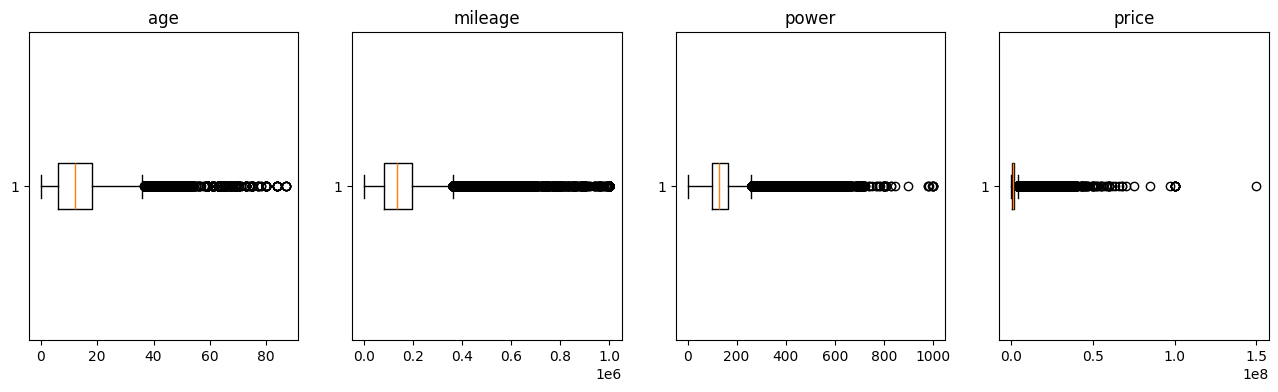

In [15]:
col_num = ['age', 'mileage', 'power', 'price']
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i in range(len(col_num)):
    ax[i].set_title(col_num[i])
    ax[i].boxplot(newdf[col_num[i]], vert=False)
plt.show()

По ящикам с усами видно, что у всех количественных признаков много значений за правым усом. Сильнее всего выделяются пробег (до 1 млн км), мощность (почти до 1000 л.с.) и цена (до 150 млн руб.). Часть таких значений может относиться к реальным дорогим или мощным автомобилям, но они сильно растягивают распределение. Поэтому удалю выбросы по пробегу и мощности.

### Метод 3 стандартных отклонений

Удалю выбросы по пробегу: объявления, в которых пробег отличается от среднего больше чем на 3 стандартных отклонения.

In [16]:
avg = newdf['mileage'].mean()
std = newdf['mileage'].std()
left = avg - 3 * std
right = avg + 3 * std
df_std = newdf[newdf['mileage'].between(left, right)]
left, right, newdf.shape[0] - df_std.shape[0]

(np.float64(-133503.70120559962), np.float64(416731.3506416078), 7347)

Верхняя граница составила около 417 тыс. км, а нижняя получилась отрицательной, поэтому удаляются только автомобили с очень большим пробегом. Таких объявлений 7347. Результат сохранила в `df_std`.

### Метод 1.5 IQR

Далее удалю выбросы по мощности методом 1,5 межквартильного размаха (IQR) из таблицы `df_std`.

In [17]:
Q1 = df_std['power'].quantile(0.25)
Q3 = df_std['power'].quantile(0.75)
IQR = Q3 - Q1
left = Q1 - 1.5 * IQR
right = Q3 + 1.5 * IQR
df_clean = df_std[df_std['power'].between(left, right)].copy()
left, right, df_std.shape[0] - df_clean.shape[0]

(np.float64(0.5), np.float64(260.5), 45225)

Границы для мощности составили от 0,5 до 260,5 л.с., удалено 45 225 объявлений. Результат сохранила в `df_clean`, в этой таблице осталось 897 885 объявлений. Дальше работаю с ней.

Цену по границам не очищаю, так как это целевая переменная. Вместо этого дальше буду использовать её логарифм.

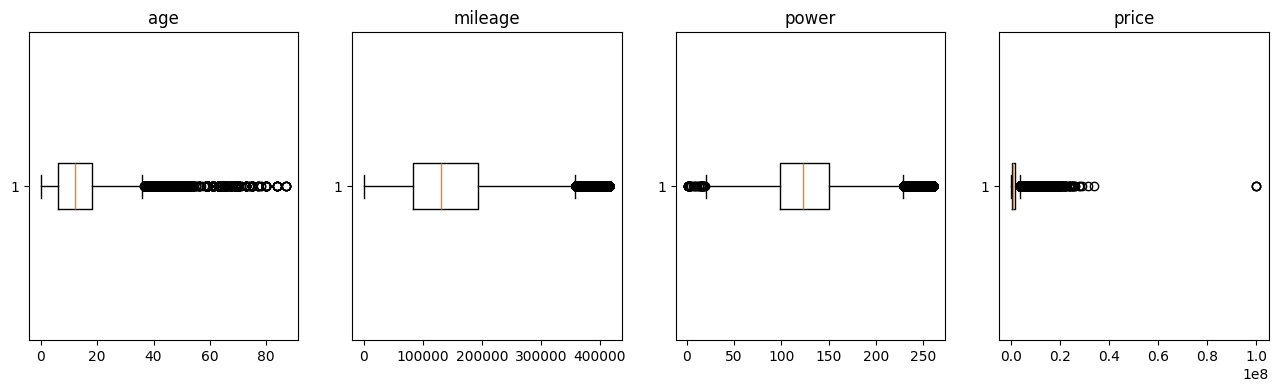

In [18]:
col_num = ['age', 'mileage', 'power', 'price']
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i in range(len(col_num)):
    ax[i].set_title(col_num[i])
    ax[i].boxplot(df_clean[col_num[i]], vert=False)
plt.show()

После очистки у пробега и мощности остались точки за усами, но они расположены близко к заданным границам: квартили новой таблицы изменились, поэтому изменились и усы. У мощности слева остались значения меньше 20 л.с., скорее всего, это ошибки в объявлениях. Возраст я не очищала, поэтому в данных остаются очень старые автомобили (до 87 лет). Цена тоже не очищалась, и в ней остаются объявления до 100 млн руб.

## Новые признаки

Создам новые признаки, которые понадобятся в дальнейшем анализе:

In [19]:
df_clean['ln_price'] = np.log(df_clean['price'])

top_brands = df_clean['brand'].value_counts().head(10).index.tolist()
df_clean['brand_group'] = df_clean['brand'].apply(lambda x: x if x in top_brands else 'Другие')

def age_group(x):
    if x <= 10:
        return 'до 10 лет'
    elif x <= 20:
        return '11-20 лет'
    else:
        return 'старше 20 лет'
df_clean['age_group'] = df_clean['age'].apply(age_group)
df_clean['gearbox'] = df_clean['transmission'].apply(lambda x: 'механика' if x == 'Механика' else 'автомат')
df_clean = df_clean.drop(columns=['brand', 'name'])
df_clean.head()

,bodyType,fuelType,mileage,transmission,power,price,age,ln_price,brand_group,age_group,gearbox
1082883,Минивэн,Дизель,57000.0,АКПП,150.0,2899000,5.0,14.879876,Другие,до 10 лет,автомат
1082888,Универсал,Бензин,115000.0,АКПП,150.0,899000,15.0,13.709038,Ford,11-20 лет,автомат
59594,Универсал,Бензин,80000.0,АКПП,109.0,545000,18.0,13.208541,Toyota,11-20 лет,автомат
59611,Седан,Бензин,150000.0,АКПП,167.0,860000,16.0,13.664688,Toyota,11-20 лет,автомат
59610,Джип 5 дв.,Бензин,250000.0,АКПП,230.0,950000,20.0,13.764217,Другие,11-20 лет,автомат


| Признак | Описание | Формат | Тип |
|---|---|---|---|
| `age` | возраст автомобиля на 2023 год, лет | float64 | количественный дискретный |
| `ln_price` | натуральный логарифм цены | float64 | количественный непрерывный |
| `brand_group` | марка: 10 самых частых, остальные в группе "Другие" | object | категориальный номинальный |
| `age_group` | до 10 лет / 11-20 лет / старше 20 лет | object | категориальный порядковый |
| `gearbox` | механика или автомат (АКПП, вариатор, робот) | object | категориальный бинарный |

После заполнения пропусков медианами у части автомобилей возраст может быть дробным, но по смыслу этот признак дискретный.

Исходные признаки `brand` и `name` дальше не использую: вместо марки теперь используется `brand_group`, а модель была нужна только для заполнения пропусков (у неё больше 2000 уникальных значений).

## Визуализация

### Количественные признаки

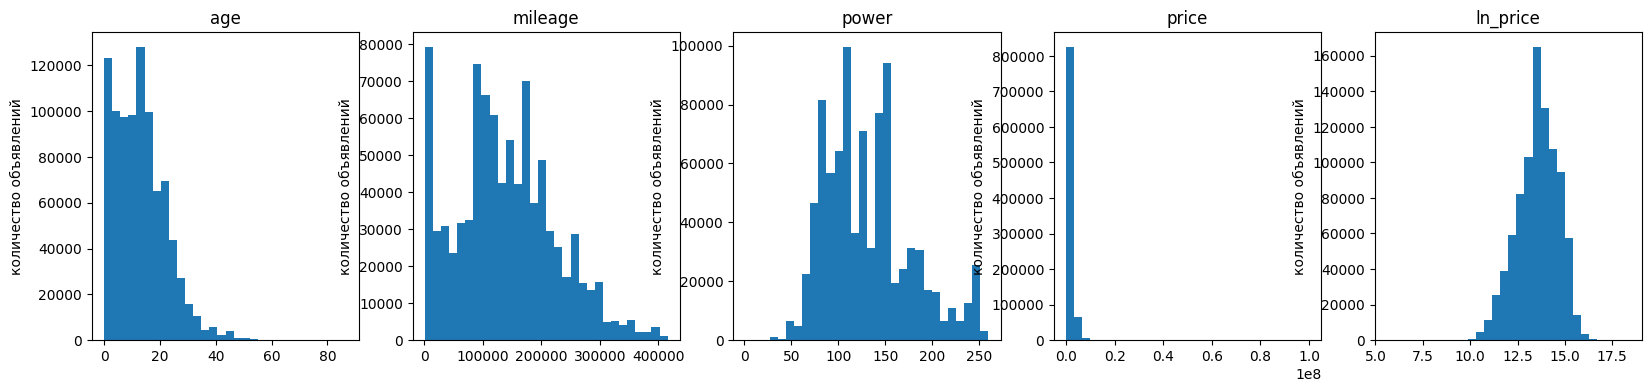

In [20]:
col_num = ['age', 'mileage', 'power', 'price', 'ln_price']
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for i in range(len(col_num)):
    ax[i].set_title(col_num[i])
    ax[i].set_ylabel('количество объявлений')
    ax[i].hist(df_clean[col_num[i]], bins=30)
plt.show()

Распределения возраста и пробега несимметричные, со скосом вправо: большинству автомобилей меньше 20 лет, а пробег чаще всего находится в пределах от 80 до 200 тыс. км. У пробега отдельно выделяется столбец около нуля,но это логично,тк в выборке есть и новые автомобили. Высокие столбцы у возраста в районе 12-15 лет и часть пиков у пробега появились в том числе из-за заполнения пропусков медианами. У мощности несколько пиков (около 85, 110 и 150 л.с.), скорее всего, они соответствуют самым распространённым двигателям. Распределение цены сильно скошено вправо: почти все объявления попали в первый столбец, а дорогих автомобилей очень мало. Распределение логарифма цены гораздо ближе к симметричному и похоже на нормальное, поэтому в модели буду предсказывать именно логарифм цены.

### Категориальные признаки

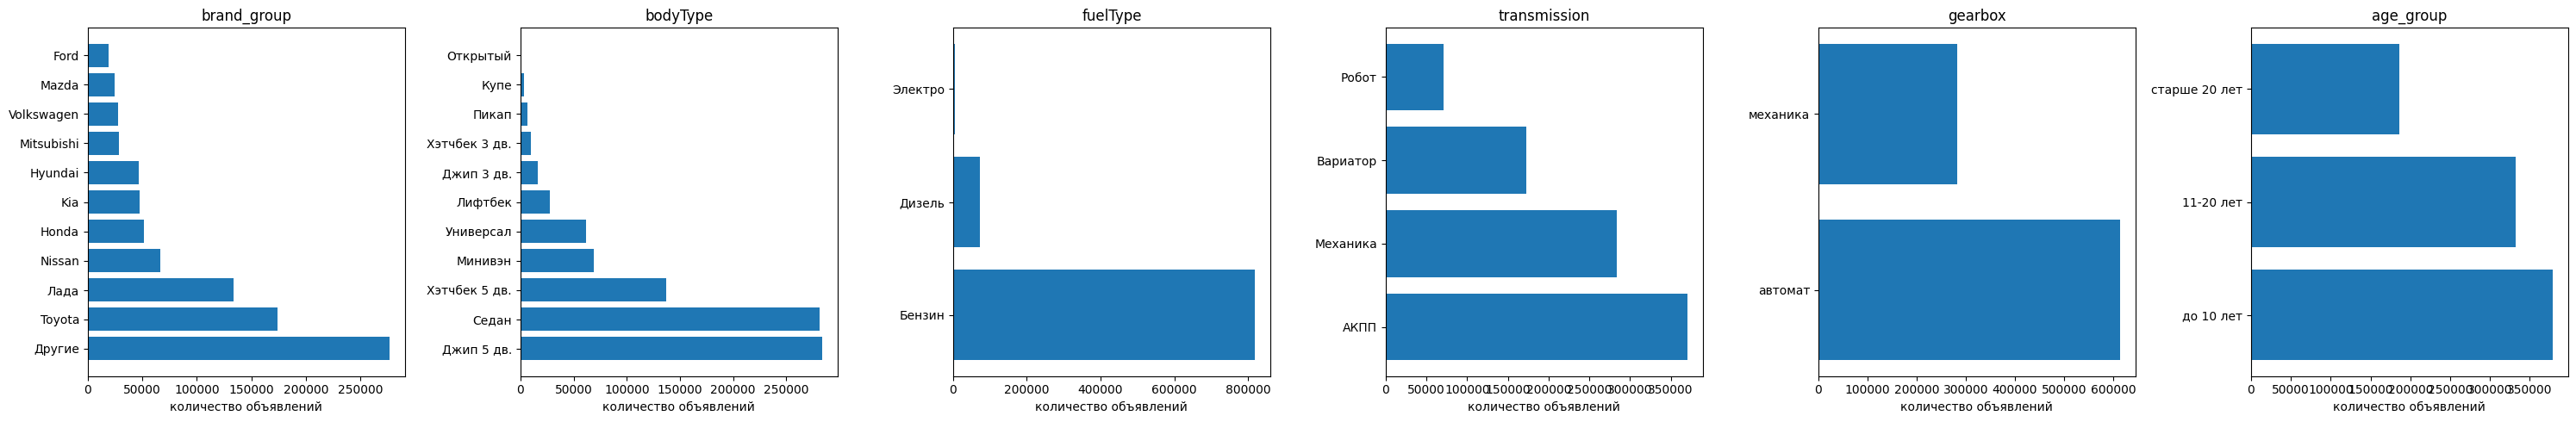

In [21]:
col_cat = ['brand_group', 'bodyType', 'fuelType', 'transmission', 'gearbox', 'age_group']
fig, ax = plt.subplots(1, 6, figsize=(30, 5))
for i in range(len(col_cat)):
    ax[i].set_title(col_cat[i])
    ax[i].set_xlabel('количество объявлений')
    freq = df_clean[col_cat[i]].value_counts()
    ax[i].barh(freq.index, freq.values)
plt.tight_layout()  # чтобы подписи соседних графиков не накладывались
plt.show()

Почти треть объявлений относится к группе "Другие", а среди отдельных марок чаще всего встречаются Toyota и Лада. Самые распространённые типы кузова - пятидверный джип и седан (их почти поровну), на третьем месте пятидверный хэтчбек. Подавляющее большинство автомобилей бензиновые, дизельных значительно меньше, а электромобилей очень мало. Самая частая коробка передач - АКПП, на втором месте механика, вариатор и робот встречаются реже. Если объединить все автоматические коробки, то на автоматы приходится больше двух третей объявлений. По возрасту больше всего автомобилей до 10 лет, а старше 20 лет - примерно пятая часть.

### Скрипичные графики

Посмотрю, как распределён логарифм цены внутри каждой категории. Для ускорения построения графиков возьму случайную подвыборку из 5000 объявлений.

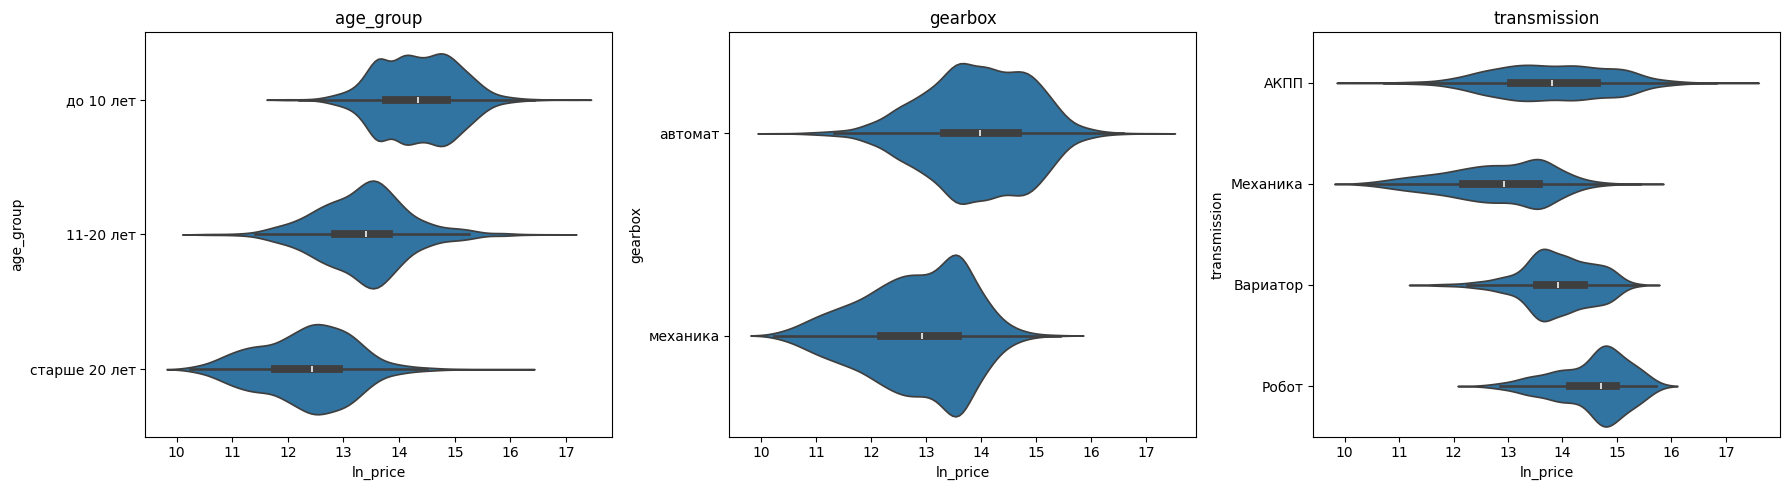

In [22]:
df_sample = df_clean.sample(5000, random_state=42)
col_cat = ['age_group', 'gearbox', 'transmission']
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i in range(len(col_cat)):
    ax[i].set_title(col_cat[i])
    sns.violinplot(data=df_sample, x='ln_price', y=col_cat[i], ax=ax[i])
plt.tight_layout()
plt.show()

Чем новее автомобиль, тем он дороже: у машин до 10 лет распределение логарифма цены заметно сдвинуто вправо, а у машин старше 20 лет - влево. Автомобили с механической коробкой в целом дешевле автомобилей с автоматом, и разброс цен у них больше. Среди отдельных типов коробки самые дорогие автомобили с роботом, затем идут вариатор и АКПП, при этом у АКПП самый большой разброс цен. Распределения в группах сильно пересекаются, поэтому по одному признаку нельзя точно определить цену.

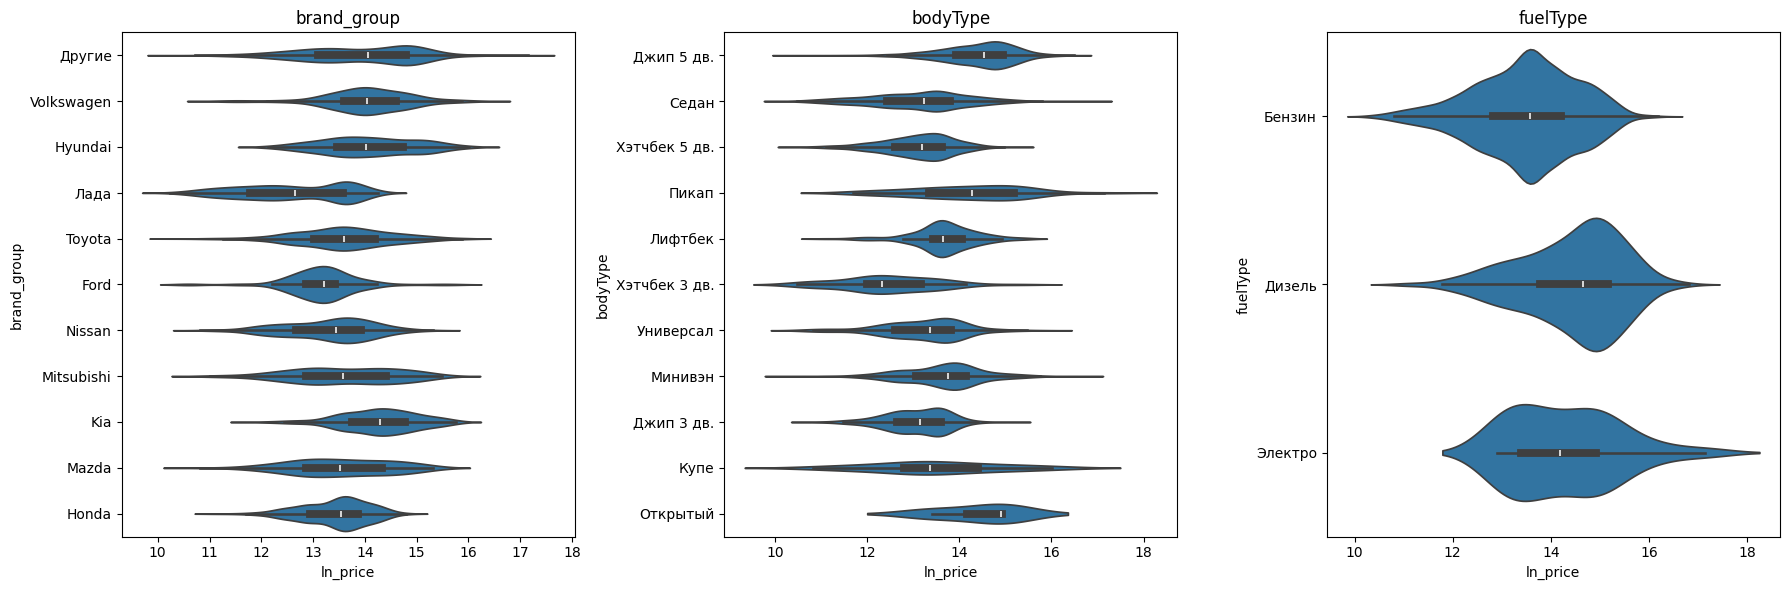

In [23]:
col_cat = ['brand_group', 'bodyType', 'fuelType']
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for i in range(len(col_cat)):
    ax[i].set_title(col_cat[i])
    sns.violinplot(data=df_sample, x='ln_price', y=col_cat[i], ax=ax[i])
plt.tight_layout()
plt.show()

Самые дешёвые автомобили среди марок - Лада, её распределение заметно сдвинуто влево. Ford и Nissan также в среднем дешевле остальных марок, а дороже всего Kia, Hyundai, Volkswagen и группа "Другие", в которую входят в том числе дорогие марки. По типу кузова дороже всего пятидверные джипы, пикапы и открытые автомобили, а дешевле всего трёхдверные хэтчбеки. У купе один из самых больших разбросов цен. Дизельные автомобили в целом дороже бензиновых. Электромобили по медиане тоже дороже бензиновых.
Для количественных признаков скрипичный график напрямую не строится, поэтому связь цены с возрастом показана через возрастные группы, а связь с пробегом и мощностью рассмотрена в разделе "Корреляция".

## Описательные статистики

### Целевой признак

In [24]:
def iqr(col):
    return col.quantile(0.75) - col.quantile(0.25)
def razmah(col):
    return col.max() - col.min()
df_clean[['price', 'ln_price']].agg(['mean', 'median', 'min', 'max', razmah, 'std', 'var', iqr]).round(2)

,price,ln_price
mean,1.290729e+06,13.57
median,8.300000e+05,13.63
min,2.700000e+02,5.60
max,1.000000e+08,18.42
razmah,9.999973e+07,12.82
std,1.394751e+06,1.07
var,1.945331e+12,1.15
iqr,1.305000e+06,1.47


In [25]:
df_clean[['price', 'ln_price']].quantile([0.25, 0.75])

,price,ln_price
0.25,390000.0,12.873902
0.75,1695000.0,14.343193


In [26]:
df_clean[['price', 'ln_price']].mode().iloc[0]

,0
price,350000.000000
ln_price,12.765688


- Средняя цена составляет 1 290 729 руб., медиана - 830 000 руб. Среднее заметно больше медианы, так как дорогие автомобили увеличивают среднее значение. Это говорит о скошенности распределения вправо.
- Мода цены - 350 000 руб. Мода меньше медианы и среднего, что также подтверждает скошенность вправо.
- Половина объявлений находится в диапазоне от 390 000 до 1 695 000 руб. (первый и третий квартили), межквартильный размах равен 1 305 000 руб.
- Минимальная цена - 270 руб., максимальная - около 100 млн руб., размах почти 100 млн руб. Обе крайние цены, скорее всего, являются ошибками или условными значениями.
- Стандартное отклонение - 1 394 751 руб., оно больше среднего значения, то есть разброс цен очень большой. Дисперсия равна 1,95·10¹² руб.², её отдельно не интерпретирую, так как она измеряется в квадратных рублях.
- У логарифма цены среднее (13,57) и медиана (13,63) почти совпадают, стандартное отклонение равно 1,07, межквартильный размах - 1,47, минимум - 5,60, максимум - 18,42. Распределение логарифма цены значительно симметричнее, чем распределение самой цены.

### Предикторы

In [27]:
df_clean[['age', 'mileage', 'power']].agg(['mean', 'median', 'min', 'max', razmah, 'std', 'var', iqr]).round(2)

,age,mileage,power
mean,13.04,1.384025e+05,131.25
median,12.00,1.300000e+05,123.00
min,0.00,1.000000e+03,1.00
max,87.00,4.160000e+05,260.00
razmah,87.00,4.150000e+05,259.00
std,9.17,8.523234e+04,45.92
var,84.16,7.264552e+09,2109.11
iqr,12.00,1.100000e+05,52.00


In [28]:
df_clean[['age', 'mileage', 'power']].mode().iloc[0]

,0
age,1.0
mileage,1000.0
power,150.0


- **age**: средний возраст автомобиля - 13 лет, медиана - 12 лет, мода - 1 год. Межквартильный размах равен 12 годам, стандартное отклонение - 9,2 года. Минимальный возраст 0 лет (новые автомобили), максимальный - 87 лет, размах - 87 лет.
- **mileage**: средний пробег - 138 403 км, медиана - 130 000 км. Значения близки, поэтому скошенность небольшая. Мода - 1000 км: так обычно указывают пробег новых автомобилей. Межквартильный размах равен 110 000 км, стандартное отклонение - 85 232 км. Минимум - 1000 км, максимум - 416 000 км (граница после удаления выбросов), размах - 415 000 км.
- **power**: средняя мощность - 131 л.с., медиана - 123 л.с., мода - 150 л.с. Межквартильный размах - 52 л.с., стандартное отклонение - 46 л.с. Максимум 260 л.с. определяется границей удаления выбросов, а минимум 1 л.с., скорее всего, является ошибкой в объявлении. Размах - 259 л.с.

Дисперсии отдельно не интерпретирую, так как они измеряются в квадратах единиц признаков (лет², км², л.с.²). Для оценки разброса удобнее использовать стандартное отклонение.

In [29]:
df_clean[['brand_group', 'bodyType', 'fuelType', 'transmission', 'gearbox', 'age_group']].describe()

,brand_group,bodyType,fuelType,transmission,gearbox,age_group
count,897885,897885,897885,897885,897885,897885
unique,11,11,3,4,2,3
top,Другие,Джип 5 дв.,Бензин,АКПП,автомат,до 10 лет
freq,277257,284105,819690,370999,614601,379179


Для категориальных признаков считаю только моду и количество категорий, так как среднее для них не имеет смысла.

- **brand_group**: 11 категорий, чаще всего встречается группа "Другие" (277 257 объявлений, 30,9%). Среди отдельных марок лидирует Toyota.
- **bodyType**: 11 типов кузова, самый частый - пятидверный джип (31,6%), седанов почти столько же.
- **fuelType**: 3 типа топлива, бензиновых автомобилей 91,3%.
- **transmission**: 4 типа коробки передач, мода - АКПП (41,3%).
- **gearbox**: 2 категории, чаще встречается автомат (68,4%).
- **age_group**: 3 группы, самая частая - автомобили до 10 лет (42,2%).

## Перекодирование данных

### One-Hot: бинарный признак

In [30]:
df_clean = pd.get_dummies(df_clean, columns=['gearbox'], drop_first=True, dtype=int)
df_clean['gearbox_механика'].value_counts()

,count
gearbox_механика,
0,614601
1,283284


`gearbox_механика` = 1, если коробка механическая, и 0, если автоматическая.

### LabelEncoder

In [31]:
from sklearn.preprocessing import LabelEncoder

df_clean['brand_label'] = LabelEncoder().fit_transform(df_clean['brand_group'])
df_clean[['brand_group', 'brand_label']].drop_duplicates().sort_values('brand_label')

,brand_group,brand_label
1082888,Ford,0
59556,Honda,1
878900,Hyundai,2
249179,Kia,3
402739,Mazda,4
109154,Mitsubishi,5
59603,Nissan,6
59594,Toyota,7
109143,Volkswagen,8
1082883,Другие,9


Каждой марке присвоен свой номер (по алфавиту). Между марками нет порядка, поэтому эти коды я не использую в регрессии.

### OrdinalEncoder

In [32]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories=[['до 10 лет', '11-20 лет', 'старше 20 лет']])
df_clean['age_group_ord'] = encoder.fit_transform(df_clean[['age_group']]).astype(int)
df_clean[['age_group', 'age_group_ord']].drop_duplicates().sort_values('age_group_ord')

,age_group,age_group_ord
1082883,до 10 лет,0
1082888,11-20 лет,1
59593,старше 20 лет,2


Возрастные группы закодированы по порядку: 0 - до 10 лет, 1 - 11-20 лет, 2 - старше 20 лет.

### One-Hot для регрессии

Для регрессии закодирую марку, кузов, топливо и коробку передач методом One-Hot. В каждом признаке одну категорию убираю (`drop_first=True`): она становится базовой, и с ней сравниваются остальные категории. Если оставить все категории, они будут дублировать свободный коэффициент модели (мультиколлинеарность).

In [33]:
df_model = pd.get_dummies(df_clean, columns=['brand_group', 'bodyType', 'fuelType', 'transmission'],
                          drop_first=True, dtype=int)
df_model.columns.tolist()

['mileage',
 'power',
 'price',
 'age',
 'ln_price',
 'age_group',
 'gearbox_механика',
 'brand_label',
 'age_group_ord',
 'brand_group_Honda',
 'brand_group_Hyundai',
 'brand_group_Kia',
 'brand_group_Mazda',
 'brand_group_Mitsubishi',
 'brand_group_Nissan',
 'brand_group_Toyota',
 'brand_group_Volkswagen',
 'brand_group_Другие',
 'brand_group_Лада',
 'bodyType_Джип 5 дв.',
 'bodyType_Купе',
 'bodyType_Лифтбек',
 'bodyType_Минивэн',
 'bodyType_Открытый',
 'bodyType_Пикап',
 'bodyType_Седан',
 'bodyType_Универсал',
 'bodyType_Хэтчбек 3 дв.',
 'bodyType_Хэтчбек 5 дв.',
 'fuelType_Дизель',
 'fuelType_Электро',
 'transmission_Вариатор',
 'transmission_Механика',
 'transmission_Робот']

Базовые категории (их нет среди столбцов): марка Ford, кузов "Джип 3 дв.", топливо "Бензин" и коробка "АКПП". Коэффициенты при этих признаках дальше сравниваю именно с ними.

## Корреляция

### Парная корреляция

In [34]:
df_clean['age'].corr(df_clean['ln_price']).round(2)

np.float64(-0.73)

Коэффициент корреляции Пирсона между возрастом автомобиля и логарифмом цены равен -0,73: чем старше автомобиль, тем ниже его цена. По модулю коэффициент больше 0,7, поэтому линейная связь сильная.

### Корреляционная матрица

Рассчитаю корреляцию Спирмена с логарифмом цены для всех признаков, которые войдут в модель, включая закодированные категории. Использую корреляцию Спирмена, так как среди признаков много бинарных и она устойчива к выбросам.

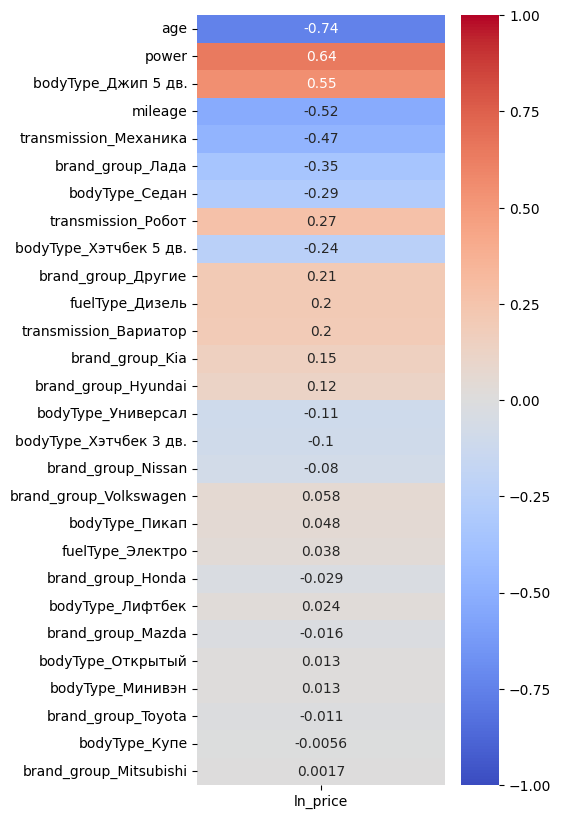

In [35]:
X = df_model.drop(columns=['price', 'ln_price', 'age_group', 'brand_label', 'age_group_ord', 'gearbox_механика'])  # признаки модели
y = df_model['ln_price']

corr = df_model[X.columns.tolist() + ['ln_price']].corr(method='spearman')
corr_target = corr[['ln_price']].drop('ln_price').sort_values('ln_price', key=abs, ascending=False)

plt.figure(figsize=(4, 10))
sns.heatmap(corr_target,
            annot=True,
            vmin=-1,
            vmax=1,
            cmap='coolwarm')
plt.show()

Сильнее всего с логарифмом цены связан возраст (-0,74, сильная обратная связь). Далее идут мощность (0,64) и пятидверный джип (0,55) - умеренная прямая связь, а также пробег (-0,52) и механическая коробка (-0,47) - умеренная обратная связь. У Лады (-0,35) связь тоже умеренная, а у седана (-0,29), робота (0,27) и остальных марок и кузовов связь слабая, по модулю меньше 0,3.

### Топ-5 признаков

In [36]:
corr_target.head(5)

,ln_price
age,-0.743912
power,0.641898
bodyType_Джип 5 дв.,0.550754
mileage,-0.523851
transmission_Механика,-0.472254


Топ-5 признаков по силе связи с логарифмом цены: возраст (-0,74), мощность (0,64), кузов "Джип 5 дв." (0,55), пробег (-0,52) и механическая коробка (-0,47). Из категорий в топ попали пятидверные джипы, которые обычно дороже, и механическая коробка, с которой автомобили обычно дешевле. Остальные признаки тоже оставлю в модели, так как вместе с другими они могут улучшить прогноз.

## Масштабирование данных

Количественные признаки измерены в разных единицах (годы, километры, л.с.). Нормализую их с помощью StandardScaler: из каждого значения вычитается среднее, и результат делится на стандартное отклонение. Бинарные признаки (0/1) не масштабирую.

In [37]:
from sklearn.preprocessing import StandardScaler

col_num = ['age', 'mileage', 'power']
X_sc = X.copy()
X_sc[col_num] = StandardScaler().fit_transform(X_sc[col_num])
X_sc[col_num].agg(['mean', 'std']).round(2)

,age,mileage,power
mean,-0.0,0.0,0.0
std,1.0,1.0,1.0


После масштабирования среднее количественных признаков равно 0, а стандартное отклонение равно 1. Для интерпретации коэффициентов регрессии сохраню стандартные отклонения признаков до масштабирования:

In [38]:
X[col_num].std().round(2)

,0
age,9.17
mileage,85232.34
power,45.92


## Линейная регрессия

Я хочу построить модель, которая предсказывает логарифм цены автомобиля по его возрасту, пробегу, мощности, марке, типу кузова, топливу и коробке передач. Логарифм использую, так как распределение цены сильно скошено вправо, а распределение логарифма цены почти симметричное.

ln(price) = w0 + w1 · age + w2 · mileage + w3 · power + коэффициенты при марке, кузове, топливе и коробке

Разделю масштабированные данные на тренировочную (80%) и тестовую (20%) выборки. Модель обучаю на тренировочной выборке, а качество проверяю на тестовой.

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_sc, y,
                                                    test_size=0.2,
                                                    random_state=42)

In [40]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train, y_train)

In [41]:
model.intercept_

np.float64(14.037162061371246)

In [42]:
coef = pd.DataFrame({'коэффициент': model.coef_,
                     'изменение цены, %': (np.exp(model.coef_) - 1) * 100},
                    index=X_train.columns)
coef.round(3)

,коэффициент,"изменение цены, %"
mileage,-0.187,-17.072
power,0.355,42.565
age,-0.518,-40.434
brand_group_Honda,-0.013,-1.303
brand_group_Hyundai,0.074,7.711
brand_group_Kia,0.057,5.839
brand_group_Mazda,0.002,0.234
brand_group_Mitsubishi,-0.036,-3.566
brand_group_Nissan,-0.182,-16.615
brand_group_Toyota,0.137,14.698


### Уравнение модели

ln(price) = 14.037 - 0.187 · mileage + 0.355 · power - 0.518 · age - 0.013 · Honda + 0.074 · Hyundai + 0.057 · Kia + 0.002 · Mazda - 0.036 · Mitsubishi - 0.182 · Nissan + 0.137 · Toyota + 0.094 · Volkswagen - 0.078 · Другие - 0.390 · Лада - 0.268 · Джип 5 дв. - 0.339 · Купе - 0.288 · Лифтбек - 0.297 · Минивэн - 0.047 · Открытый - 0.276 · Пикап - 0.498 · Седан - 0.430 · Универсал - 0.626 · Хэтчбек 3 дв. - 0.535 · Хэтчбек 5 дв. + 0.324 · Дизель + 0.260 · Электро + 0.079 · Вариатор - 0.197 · Механика + 0.066 · Робот

Здесь age, mileage и power - отмасштабированные значения, а остальные переменные равны 1, если у машины такая марка, кузов, топливо или коробка, и 0, если нет.

### Интерпретация коэффициентов

Так как целевая переменная - логарифм цены, коэффициент $w$ перевожу в проценты изменения цены по формуле (e^w-1)*100%
Количественные признаки отмасштабированы, поэтому их коэффициенты показывают изменение цены при росте признака на одно стандартное отклонение. Все коэффициенты интерпретирую при прочих равных.

- **Свободный коэффициент**: это логарифм цены машины со средними возрастом, пробегом и мощностью, марки Ford, с кузовом "Джип 3 дв.", бензиновым двигателем и АКПП. В рублях это $e^{14.037} \approx$ 1 248 136 руб.
- **age** (-0,518): при увеличении возраста на 9,2 года цена в среднем снижается на 40,4%.
- **mileage** (-0,187): при увеличении пробега на 85 232 км цена в среднем снижается на 17,1%.
- **power** (0,355): при увеличении мощности на 45,9 л.с. цена в среднем растёт на 42,6%.

Марка (по сравнению с Ford):
- **Honda** (-0,013): машины Honda дешевле на 1,3%, то есть почти не отличаются от Ford.
- **Hyundai** (0,074): машины Hyundai дороже на 7,7%.
- **Kia** (0,057): машины Kia дороже на 5,8%.
- **Mazda** (0,002): машины Mazda дороже на 0,2%, разницы с Ford практически нет.
- **Mitsubishi** (-0,036): машины Mitsubishi дешевле на 3,6%.
- **Nissan** (-0,182): машины Nissan дешевле на 16,6%.
- **Toyota** (0,137): машины Toyota дороже на 14,7%.
- **Volkswagen** (0,094): машины Volkswagen дороже на 9,9%.
- **Другие** (-0,078): машины остальных марок дешевле на 7,5%.
- **Лада** (-0,390): автомобили Лада дешевле на 32,3%.

Кузов (по сравнению с "Джип 3 дв."):
- **Джип 5 дв.** (-0,268): дешевле на 23,5%.
- **Купе** (-0,339): дешевле на 28,8%.
- **Лифтбек** (-0,288): дешевле на 25,0%.
- **Минивэн** (-0,297): дешевле на 25,7%.
- **Открытый** (-0,047): дешевле на 4,6%.
- **Пикап** (-0,276): дешевле на 24,1%.
- **Седан** (-0,498): дешевле на 39,2%.
- **Универсал** (-0,430): дешевле на 35,0%.
- **Хэтчбек 3 дв.** (-0,626): дешевле на 46,5%.
- **Хэтчбек 5 дв.** (-0,535): дешевле на 41,5%.

Все кузова получились дешевле трёхдверного джипа.

Топливо (по сравнению с бензином):
- **Дизель** (0,324): дизельные машины дороже на 38,2%.
- **Электро** (0,260): электромобили дороже на 29,6%, но их в данных очень мало.

Коробка передач (по сравнению с АКПП):
- **Вариатор** (0,079): машины с вариатором дороже на 8,2%.
- **Механика** (-0,197): машины с механикой дешевле на 17,9%.
- **Робот** (0,066): машины с роботом дороже на 6,8%.

### Метрики качества

In [43]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
y_pred = model.predict(X_test)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred)
(MSE, MAE, R2)

(0.21456944956830648, 0.3279901468791238, 0.8136888470420252)

In [44]:
mean_absolute_error(np.exp(y_test), np.exp(y_pred))

366736.1922896446

- $MSE$ = 0,215: средний квадрат ошибки в предсказании логарифма цены.
- $MAE$ = 0,328: в среднем модель ошибается в предсказании логарифма цены на 0,33.
- $R^2$ = 0,81: модель объясняет 81% вариации логарифма цены на тестовой выборке.
- $MAE$ в рублях = 366 736: если перевести прогноз обратно в рубли, модель в среднем ошибается примерно на 367 тыс. руб. Для дешёвых автомобилей это большая ошибка, для дорогих - менее существенная. В модели нет данных о состоянии автомобиля, комплектации и истории, поэтому точнее предсказать цену сложно.

## Тестирование гипотез

Все тесты провожу по таблице `df_clean`. Выводы делаю на уровнях значимости 1%, 5% и 10%.

In [45]:
from scipy import stats
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest

### Тест Шапиро-Уилка

Проверю, распределены ли нормально логарифм цены и цены машин с механической и автоматической коробкой (их буду сравнивать дальше). Тест рассчитан на выборки до 5000 наблюдений, поэтому беру случайные 5000 значений.

H0 - данные распределены нормаально, Н1 - данные распределены не нормально

In [46]:
manual = df_clean[df_clean['gearbox_механика'] == 1]['price']
auto = df_clean[df_clean['gearbox_механика'] == 0]['price']

res1 = stats.shapiro(df_clean['ln_price'].sample(5000, random_state=42))
res2 = stats.shapiro(manual.sample(5000, random_state=42))
res3 = stats.shapiro(auto.sample(5000, random_state=42))
res1.pvalue, res2.pvalue, res3.pvalue

(np.float64(1.2332818680217854e-15),
 np.float64(4.0524266501413255e-62),
 np.float64(7.813857064891267e-62))

**Вывод:** во всех трёх тестах p-value очень маленькие (меньше 10⁻¹⁴), поэтому гипотеза о нормальном распределении отвергается на уровнях значимости 1%, 5% и 10%. Даже логарифм цены, который на гистограмме выглядит симметричным, по тесту не является нормально распределённым. Так как выборки очень большие, в t-тестах далее опираюсь на то, что выборочное среднее распределено приблизительно нормально.

### Одновыборочный t-тест

Проверю, отличается ли средняя цена в объявлениях от 1 млн рублей. Дисперсия генеральной совокупности неизвестна, поэтому использую t-тест.

H0: μ(price) = 1 000 000

H1: μ(price) ≠ 1 000 000

In [47]:
res = stats.ttest_1samp(df_clean['price'], popmean=1000000, alternative='two-sided')
res

TtestResult(statistic=np.float64(197.51562276704436), pvalue=np.float64(0.0), df=np.int64(897884))

**Вывод:** p-value практически равно 0, значит нулевая гипотеза отвергается на уровнях значимости 1%, 5% и 10%. Средняя цена в объявлениях отличается от 1 млн руб.: она равна 1 291 тыс. руб., то есть больше миллиона (t-статистика положительная).

### Z-тест

Проверю гипотезу о том, что средний пробег меньше 150 000 км. Буду считать, что выборочная дисперсия пробега равна дисперсии генеральной совокупности, так как выборка очень большая.

H0: μ(mileage) = 150 000

H1: μ(mileage) < 150 000

In [48]:
res = ztest(df_clean['mileage'], value=150000, alternative='smaller')
res

(np.float64(-128.93477526090362), np.float64(0.0))

**Вывод:** p-value практически равно 0, поэтому нулевая гипотеза отвергается на уровнях значимости 1%, 5% и 10%. Средний пробег действительно меньше 150 000 км: в выборке он равен 138 403 км.

### Двухвыборочный t-тест

Проверю, что машины с механической коробкой в среднем дешевле машин с автоматической. Выборки не связаны (это разные объявления). Дисперсии цен в группах могут отличаться, поэтому ставлю `equal_var=False`.

H0: μ(manual) = μ(auto)

H1: μ(manual) < μ(auto)

In [49]:
res = stats.ttest_ind(manual, auto, equal_var=False, alternative='less')
res

TtestResult(statistic=np.float64(-498.8567825238684), pvalue=np.float64(0.0), df=np.float64(842471.3157877729))

**Вывод:** p-value практически равно 0, поэтому нулевая гипотеза отвергается на уровнях значимости 1%, 5% и 10%. Автомобили с механической коробкой в среднем действительно дешевле. При этом механика чаще встречается у старых автомобилей (это видно по критерию хи-квадрат ниже), поэтому разница в цене связана не только с типом коробки.

### Парный t-тест

Парный t-тест нужен, чтобы сравнить два измерения одного и того же объекта. Например, можно было бы проверить, отличается ли цена одной и той же машины до и после какого-то события:

H0: μ(before) = μ(after)

H1: μ(before) ≠ μ(after)

Но провести такой тест на моих данных не получится. Каждое наблюдение - это одна машина с одной ценой, и после удаления повторов каждое объявление встречается в данных один раз. Связанных выборок (пар наблюдений одного объекта) у меня нет.

### Z-тест для одной пропорции

Проверю, что доля объявлений дороже 1 млн рублей равна половине.

H0: p = 0.5

H1: p ≠ 0.5

In [50]:
successes = df_clean[df_clean['price'] > 1000000].shape[0]
samples = df_clean.shape[0]
stat, p_value = proportions_ztest(count=successes, nobs=samples, value=0.5)
successes / samples, stat, p_value

(0.415321561224433, np.float64(-162.82924988789512), np.float64(0.0))

**Вывод:** доля объявлений дороже 1 млн руб. равна 41,5%. p-value практически равно 0, поэтому гипотеза о том, что эта доля равна 50%, отвергается на уровнях значимости 1%, 5% и 10%: дорогих объявлений меньше половины. Предпосылка теста выполняется, так как ожидаемые количества успехов и неуспехов намного больше 5.

### Z-тест для двух пропорций

Сравню долю объявлений дороже 1 млн рублей у машин до 10 лет и у машин старше 10 лет.

H0: p(young) = p(old)

H1: p(young) ≠ p(old)

In [51]:
young = df_clean[df_clean['age'] <= 10]
old = df_clean[df_clean['age'] > 10]
successes = np.array([young[young['price'] > 1000000].shape[0], old[old['price'] > 1000000].shape[0]])
samples = np.array([young.shape[0], old.shape[0]])
stat, p_value = proportions_ztest(successes, samples)
successes / samples, stat, p_value

(array([0.73237969, 0.18354906]),
 np.float64(521.2666980390853),
 np.float64(0.0))

**Вывод:** среди машин до 10 лет дороже миллиона 73,2% объявлений, а среди более старых - только 18,4%. p-value практически равно 0, нулевая гипотеза отвергается на уровнях значимости 1%, 5% и 10%: доли дорогих машин в этих группах различаются.

### Критерий Манна-Уитни

Цены по тесту Шапиро-Уилка распределены не нормально, поэтому сравню цены машин с механикой и автоматом ещё и непараметрическим тестом.

H0: распределения цен машин с механической и автоматической коробкой одинаковы

F(manual) = F(auto)

H1: распределения цен различаются

F(manual) ≠ F(auto)

In [52]:
res = stats.mannwhitneyu(manual, auto, alternative='two-sided')
res

MannwhitneyuResult(statistic=np.float64(35977979012.5), pvalue=np.float64(0.0))

**Вывод:** p-value практически равно 0, нулевая гипотеза отвергается на уровнях значимости 1%, 5% и 10%. Распределения цен машин с механикой и с автоматом различаются, это согласуется с результатом t-теста.

### Критерий хи-квадрат

Проверю, связаны ли возрастная группа машины и тип коробки передач.

H0: возрастная группа и тип коробки независимы
P(age_group, gearbox) = P(age_group) · P(gearbox)

H1: возрастная группа и тип коробки зависимы
P(age_group, gearbox) ≠ P(age_group) · P(gearbox)

In [53]:
table = df_clean.pivot_table(index='age_group',
                             columns='gearbox_механика',
                             values='price',
                             aggfunc='count')
table

gearbox_механика,0,1
age_group,,
11-20 лет,214934,117715
до 10 лет,293603,85576
старше 20 лет,106064,79993


In [54]:
result = stats.chi2_contingency(table)
result.statistic, result.pvalue

(np.float64(27713.24741932034), np.float64(0.0))

**Вывод:** p-value практически равно 0, поэтому нулевая гипотеза отвергается на уровнях значимости 1%, 5% и 10%. Возрастная группа и тип коробки связаны: среди автомобилей до 10 лет механика у 22,6%, среди автомобилей от 11 до 20 лет - у 35,4%, а среди автомобилей старше 20 лет - у 43,0%. В каждой ячейке таблицы десятки тысяч наблюдений, поэтому ожидаемые частоты значительно больше 5 и тест можно применять.

## Итоговые выводы

В работе я исследовала, от чего зависит цена автомобиля в объявлениях на Drom. После удаления повторов, заполнения пропусков и удаления выбросов по пробегу и мощности в данных осталось 897 885 объявлений.

Сильнее всего цена связана с возрастом автомобиля: корреляция с логарифмом цены равна -0,73, а графики и тесты показывают, что новые автомобили заметно дороже старых. Также цена растёт с мощностью и снижается с пробегом. Среди категориальных признаков важны коробка передач (автомобили с механикой дешевле) и тип топлива (дизельные автомобили дороже бензиновых).

Линейная регрессия для логарифма цены объясняет 81% его вариации на тестовой выборке, средняя ошибка прогноза составляет около 367 тыс. руб. Сильнее всего на прогноз влияет возраст: увеличение возраста на 9,2 года снижает цену примерно на 40% при прочих равных. Для более точного прогноза нужны данные о состоянии автомобиля и комплектации, которых в датасете нет.

Важно учитывать, что в работе использованы цены объявлений за 2023 год, а не цены реальных продаж, и часть значений года выпуска и пробега заполнена медианами.